In [1]:
#Install datasets Library
!pip install datasets
!pip install torch
!pip install tiktoken

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [2]:
import torch
import tiktoken
import os
import numpy as np
from tqdm.auto import tqdm

# Use this line of code if running on V100 / GPU temp error is presented
os.environ["CUDA_VISIBLE_DEVICES"] = "3"  # or "1" or "3" — all are clean

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla V100-PCIE-32GB


In [3]:
from datasets import load_dataset

# Tiny Stories Dataset import from hugging face: https://huggingface.co/datasets/roneneldan/TinyStories
ds = load_dataset("roneneldan/TinyStories")

# Step 2: Tokenize the Dataset

## In this step, we do the following:

### (1) Tokenize the dataset into tokenIDs.

### (2) Create "train.bin" and "validation.bin" where we will be storing the tokenIDs from the entire dataset.

### (3) We make sure the tokenIDs are stored on a disk, rather than on the RAM for effiecient compuations

In [4]:



enc = tiktoken.get_encoding("gpt2")

def process(example):
    ids = enc.encode_ordinary(example['text']) # encode_ordinary ignores any special characters 
    out = {'ids': ids, 'len': len(ids)}
    return out
    
if not os.path.exists('train.bin'): 
    tokenized = ds.map(
        process,
        remove_columns = ['text'],
        desc = "tokenizing the splits",
        num_proc = 8,
    )
    # concatenate all the ids in each dataset into one large file we can use for training
    for split, dset in tokenized.items():
        arr_len = np.sum(dset['len'], dtype = np.uint64)
        filename = f'{split}.bin'
        dtype = np.uint16 # enc.max_token_value == 50256 is < 2**16)
        arr = np.memmap(filename, dtype=dtype, mode='w+', shape=(arr_len,))
        total_batches = 1024

        idx = 0
        for batch_idx in tqdm(range(total_batches), desc = f'writing {filename}'):
            # Batch / Merge together samples for faster write
            batch = dset.shard(num_shards = total_batches, index=batch_idx, contiguous=True).with_format("numpy") # <- May be wrong check after run
            arr_batch = np.concatenate(batch['ids'])
            # Write into mmap
            arr[idx : idx + len(arr_batch)] = arr_batch
            idx += len(arr_batch)
        arr.flush()

** Step 3: Create Input-Output bathces for the dataset **

In [5]:
 def get_batch(split):
    # Recreate np.memmap for every batch to avoid a memory leak
    if split == 'train':
         data = np.memmap('train.bin', dtype=np.uint16, mode='r') # changed from 64 to 16. See if corrects
    else:
         data = np.memmap('validation.bin', dtype=np.uint16, mode='r')
        
    # Code represnetation of matrix batches with random indices
    ix = torch.randint(len(data) - block_size, (batch_size,))
    # Input Tensor
    x = torch.stack([torch.from_numpy((data[i:i+block_size]).astype(np.int64)) for i in ix])
    # Output Tensor, shifted to the right by 1 
    y = torch.stack([torch.from_numpy((data[i+1:i+1+block_size]).astype(np.int64)) for i in ix])
    if device_type == 'cuda':
        # pin array x,y, into GPU memory 
        x, y = x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
    else:
        x, y = x.to(device), y.to(device)
    return x, y

# Section 2: Processor
## Step 4: Define the SLM Model Architecture

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
from dataclasses import dataclass
from contextlib import nullcontext

# Layer Normalization: 
class LayerNorm(nn.Module):
    def __init__(self, ndim, bias):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(ndim))
        self.bias = nn.Parameter(torch.zeros(ndim)) if bias else None
    def forward(self, x):
        return F.layer_norm(x, self.weight.shape, self.weight, self.bias, 1e-5)

# Causual Attention Mechinism: 
# - Computes attention for a given sentence's tokens by comparing the tokens to themselves (self attention)
class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd, bias=config.bias)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd, bias=config.bias)
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.flash = hasattr(F, 'scaled_dot_product_attention')
        if not self.flash:
            self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                        .view(1,1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1,2) # Query
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1,2) # Key
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1,2) # Value

        if self.flash:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=None, dropout_p=self.attn_dropout.p if self.training else 0.0, is_causal=True)
        else:
            # Causual Attention Score Calculation: Q * K transpose
            # - Divide by square root of keys dimension to stabilize variance of dot product (scaler?)
            att = (q @ k.transpose(-2,-1)) * (1.0 / math.sqrt(k.size(-1)))

            # Added so token's after current token cannot "see" each other
            att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))

            # Softmax used to make each row sum to 1. The above code will convert -inf to 0
            att = F.softmax(att, dim=-1) # Changed from 1 to -1

            # Added to improve generalization performance
            att = self. attn_dropout(att)

            # Context Vector Matrix
            # - @: binary operator for matrix multiplication 
            y = att @ v
            
        y = y.transpose(1, 2).contiguous().view(B, T, C)

        #                      Adds neural network for preservation of CVM size (optional)
        y = self.resid_dropout(self.c_proj(y))
        return y
        # End of Cuasual Attention Block

# Feed Forward Neural Network
class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd, bias=config.bias) # First Layer

        # Activation Function
        # - GeLu is optional, but has promsiing results in language modeling 
        self.gelu = nn.GELU()


        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd, bias=config.bias) # Compression Layer - reduces dimensionalilty 
        self.dropout = nn.Dropout(config.dropout)
    def forward(self, x):
        return self.dropout(self.c_proj(self.gelu(self.c_fc(x))))
        
# Transformer Block
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln1 = LayerNorm(config.n_embd, config.bias) # Layer Norm 1
        self.attn = CausalSelfAttention(config) # Multi-Head Attention
        self.ln2 = LayerNorm(config.n_embd, config.bias) # Layer Norm 2
        self.mlp = MLP(config)  # Feed Foward NN

    # Shortcut connections
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

@dataclass
class GPTConfig:
    block_size: int
    vocab_size: int
    n_layer: int
    n_head: int
    n_embd: int
    dropout: float = 0.0
    bias: bool = True

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            drop = nn.Dropout(config.dropout),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = LayerNorm(config.n_embd, config.bias),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias = False) # Output Head
        self.transformer.wte.weight = self.lm_head.weight # weight tying

        self.apply(self._init_weights)
        for pn, p in self.named_parameters():
            if pn.endswith('c_proj.weight'):
                nn.init.normal_(p, mean=0.0, std=0.2 / math.sqrt(2 * config.n_layer))
                
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        device = idx.device
        b, t = idx.size()
        assert t <= self.config.block_size
        pos = torch.arange(0, t, dtype=torch.long, device=device)

        tok_emb = self.transformer.wte(idx)
        pos_emb = self.transformer.wpe(pos)
        x = self.transformer.drop(tok_emb + pos_emb)
        for block in self.transformer.h: # Transfomer block iteration
            x = block(x)
        x = self.transformer.ln_f(x) # Final Normalization Layer

        if targets is not None:
            # Logits Matrix
            logits = self.lm_head(x) # Output Head
            # Loss of output compared to target; Negative Loss Likelihood
            loss = F.cross_entropy(logits.view(-1,logits.size(-1)), targets.view(-1), ignore_index=-1)
            return logits, loss
        else:
            logits = self.lm_head(x[:, [-1], :])
            return logits, None
            
    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        # Generate tokens given a conditioning sequence.
        # idx: Tensor of shape (B, T)
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.config.block_size else idx[:, -self.config.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v,_ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float('Inf')
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

In [7]:
config = GPTConfig(
    vocab_size=50257,  # use the tokenizer's vocab size or whatever approaiate context size
    block_size=128,  
    n_layer=6, # n_layer = number of transfomer blocks
    n_head=6, # number of attention heads. Calculate attention score, Essentially number of Multi-head attn blocks
    n_embd=384, # embedding dimension
    dropout=0.1,
    bias=True
)

model = GPT(config)

## Step 5 - Loss Function

In [8]:
def estimate_loss(model):
    out = {}
    model.eval()
    with torch.inference_mode():
        for split in ['train', 'val']:
            losses = torch.zeros(eval_iters)
            for k in range(eval_iters):
                X, Y =  get_batch(split)
                with ctx:
                    logits, loss = model(X,Y)
                losses[k] = loss.item() # Mean loss
            out[split] = losses.mean()
    model.train()
    return out

# Step 6: Define SLM Training Configuration Part 1

In [9]:
# Training config

# Notes log:
# - First iteration had over fitting with:
# -- learning_rate = 1e-4
# -- min_lr = 5e-4

# Hyper parameters
learning_rate = 5e-4 # More stable training
max_iters = 60000 # Changed from 20000 to 60000. More training!!
warmup_steps = 100 # Orginally was 1000 for smoother initial train, changing to 100 for faster warmup and lr utilization
min_lr = 1e-4 # lower rate
eval_iters = 500 # increased from 100
batch_size = 32 # changed from 16; Better gradient estimate
block_size = 128 # changed from 64; captures longer range dependencies

# Equal to batch size
gradient_accumulation_steps = 32 # reduced from 50

device = "cuda" if torch.cuda.is_available() else "cpu"
device_type = 'cuda' if 'cuda' in device else 'cpu' # for later use in torch.autocast


# Currently having performace issues with code below.
# - Currently checks hardware device. May be sub optimal for this porjects purpose.
dtype = 'bfloat16' if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else 'float16'
ptdtype = {'float32': torch.float32, 'bfloat16': torch.bfloat16, 'float16': torch.float}[dtype]
ctx = nullcontext() if device_type == 'cpu' else torch.amp.autocast(device_type=device_type, dtype=ptdtype)

# -- Hardcoded dtypes
#dtype = 'float32'
#ptdtype = torch.float32
#ctx = torch.amp.autocast(device_type=device_type, dtype=torch.float32)

#orch.set_default_device(device)
torch.manual_seed(42)
print(f"Device: {device}, dtype: {dtype}")

Device: cuda, dtype: float16


# Step 7: Define SLM Training Configuration Part 2: Gradient Accumulation

In [10]:
from torch.optim.lr_scheduler import LinearLR, SequentialLR, CosineAnnealingLR

## PUT IN WEIGHT DECAY, CHANGED BETA2 to 0.95 - ??
# - Optimizer used so we don't get stuck in a local minima 
optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=learning_rate,
            betas=(0.9,0.95),
            weight_decay=0.1,
            eps=1e-9
)

def get_lr(epoch):
    if epoch < warmup_steps:
        return epoch / warmup_steps
    progress = (epoch - warmup_steps) / (max_iters - warmup_steps)
                            # Changed 0.5 to 1.0
    return max(min_lr / learning_rate, 0.5 * (1 + math.cos(math.pi * progress)))
    
#scheduler_warmup = LinearLR(optimizer, total_iters = warmup_steps) # Implement linear warmup
#scheduler_decay = CosineAnnealingLR(optimizer, T_max = max_iters - warmup_steps, eta_min = min_lr) # Implement LR decay
#scheduler = SequentialLR(optimizer, schedulers=[scheduler_warmup, scheduler_decay], milestones=[warmup_steps]) # Switch from warmup to decay

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, get_lr)
scaler  = torch.cuda.amp.GradScaler(enabled=(dtype == 'float16')) #= torch.cuda.amp.GradScaler(enabled=False) ; Currently scaler testing

In [11]:
# Cluster GPU Error Check
import subprocess
print(subprocess.check_output("hostname", shell=True).decode())
print(subprocess.check_output("nvidia-smi", shell=True).decode())

gpu-v100-01.deac.wfu.edu

Tue Apr 14 17:25:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.172.08             Driver Version: 570.172.08     CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla V100-PCIE-32GB           On  |   00000000:01:00.0 Off |                    0 |
| N/A   33C    P0             25W /  250W |       0MiB /  32768MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

# Step 8: Pre-train the SLM

In [12]:
best_val_loss = float('inf')
best_model_params_path = "best_model_params.pt"
train_loss_list, validation_loss_list = [], []

model = model.to(device) # Ensure model is on corrct device

# In training loop
for epoch in tqdm(range(max_iters)):
    if epoch % eval_iters == 0 and epoch != 0:
        #Ensure estimate_loss uses the correct device
        losses = estimate_loss(model)
        print(f"Epoch {epoch}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
        print(f"The current learning rate: {optimizer.param_groups[0]['lr']:.5f}")
        train_loss_list += [losses['train']]
        validation_loss_list += [losses['val']]

        if losses['val'] < best_val_loss:
            best_val_loss = losses['val']
            torch.save(model.state_dict(), best_model_params_path)
    # Ensure X and Y are on the correct device
    X, y = get_batch("train")
    #, y = X.to(device), y.to(device)

    with ctx:
        logits, loss = model(X,y)
        loss = loss / gradient_accumulation_steps
    scaler.scale(loss).backward()
    
    if ((epoch + 1) % gradient_accumulation_steps == 0) or (epoch + 1 == max_iters):
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        scheduler.step()

  0%|          | 0/60000 [00:00<?, ?it/s]

Epoch 500: train loss 9.9453, val loss 9.9504
The current learning rate: 0.00007
Epoch 1000: train loss 8.8822, val loss 8.8864
The current learning rate: 0.00015
Epoch 1500: train loss 7.3885, val loss 7.3919
The current learning rate: 0.00023
Epoch 2000: train loss 6.0678, val loss 6.0731
The current learning rate: 0.00031
Epoch 2500: train loss 5.5764, val loss 5.5797
The current learning rate: 0.00039
Epoch 3000: train loss 5.1644, val loss 5.1616
The current learning rate: 0.00047
Epoch 3500: train loss 4.6866, val loss 4.6876
The current learning rate: 0.00050
Epoch 4000: train loss 4.3158, val loss 4.3275
The current learning rate: 0.00050
Epoch 4500: train loss 4.0911, val loss 4.0921
The current learning rate: 0.00050
Epoch 5000: train loss 3.8908, val loss 3.9035
The current learning rate: 0.00050
Epoch 5500: train loss 3.7592, val loss 3.7614
The current learning rate: 0.00050
Epoch 6000: train loss 3.6091, val loss 3.6139
The current learning rate: 0.00050
Epoch 6500: train

In [13]:
# Cluster GPU Error Check
#import subprocess
#print(subprocess.check_output("hostname", shell=True).decode())
#print(subprocess.check_output("nvidia-smi", shell=True).decode())

# Step 9: Plot the SLM Loss Function

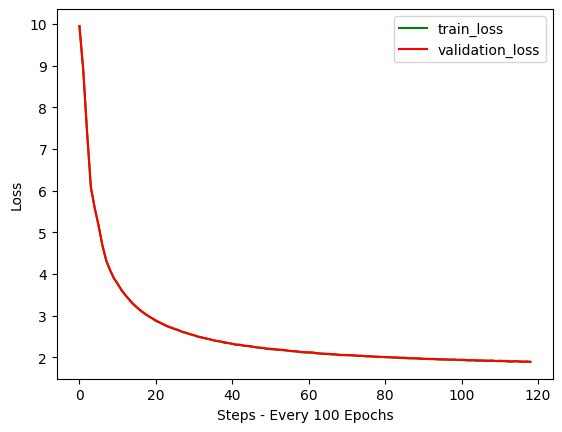

In [14]:
import matplotlib.pyplot as plt
train_loss_list_converted = [i.cpu().detach() for i in train_loss_list]
validation_list_converted = [i.cpu().detach() for i in validation_loss_list]

plt.plot(train_loss_list_converted, 'g', label='train_loss')
plt.plot(validation_list_converted, 'r', label='validation_loss')
plt.xlabel("Steps - Every 100 Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Step 10: Run SLM Inference on our trained Model

In [15]:
# Load the model
model = model
device = "cuda" if torch.cuda.is_available() else "cpu"
best_model_params_path = "best_model_params.pt"
model.load_state_dict(torch.load(best_model_params_path, map_location=torch.device(device))) # load best model states

<All keys matched successfully>

In [18]:
sentence = "The pig once looked at the moon and thought happy dreams. To his surprise"
context = (torch.tensor(enc.encode_ordinary(sentence), device=device).unsqueeze(0))
y = model.generate(context, 200)
print(enc.decode(y.squeeze().tolist()))

The pig once looked at the moon and thought happy dreams. To his surprise, he decided to climb the moon every day to see how high the moon twinkled and shone brightly. 

The little pig kept climbing until his dream came true. He was so excited he search everywhere, until he saw it again. He couldn't believe how pretty the moon had matched - it had sparkly stars and the night before! 

The little pig couldn't wait to tell his mom all of his special night. Harry knew that if he ever couldn eat his night carrying a pumpkin, anything he would make it look nice!Molly had a jealousy and she decided he had to help. She took her hammer out of the wood and carefully stretched out the wood.

Suddenly she heard a loud bang. She went up to have help and camemy wailed. 

Molly realized the broken weapon was broken! She quickly puffed and said, "I broke my part of my wood!" 

Molly gave her mum a hug and


In [ ]:
# Cell run order to reproduce without training again. 1,4,8,9,13,23